In [1]:
!pip -q install pymupdf tiktoken scikit-learn pandas transformers sentencepiece accelerate

In [2]:
from google.colab import files
from pathlib import Path
uploaded=files.upload()
pdf_files=[Path(k) for k in uploaded if k.lower().endswith('.pdf')]
assert pdf_files, 'Upload the Azerbaijan IMF report PDF.'
PDF=pdf_files[0]
OUT=Path('/content/azerbaijan_task1'); OUT.mkdir(exist_ok=True)
print('Selected:',PDF)

Saving 1azeea2024001.pdf to 1azeea2024001.pdf
Selected: 1azeea2024001.pdf


In [3]:
import re,json,time,hashlib,zipfile
import fitz,tiktoken,pandas as pd
from collections import Counter
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

enc=tiktoken.get_encoding('cl100k_base')
def clean_page(s):
    s=re.sub(r'(?m)^\s*(?:REPUBLIC OF AZERBAIJAN|INTERNATIONAL MONETARY FUND)\s*$', '',s)
    s=re.sub(r'(?m)^\s*\d{1,3}\s*$', '',s)
    s=re.sub(r'(?<=\w)-\n(?=\w)','',s)
    s=re.sub(r'(?<!\n)\n(?!\n)',' ',s)
    s=re.sub(r'[ \t]+',' ',s)
    return re.sub(r'\n{3,}','\n\n',s).strip()

doc=fitz.open(str(PDF))
pages=[{'page':i+1,'text':clean_page(p.get_text('text'))} for i,p in enumerate(doc)]
assert len(pages)>10 and sum(len(p['text']) for p in pages)>10000,'PDF appears image-only or unreadable.'
(OUT/'cleaned_text.txt').write_text('\n\n'.join(f"[PDF PAGE {p['page']}]\n{p['text']}" for p in pages),encoding='utf8')
print('Pages:',len(pages),'Extracted characters:',sum(len(p['text']) for p in pages))

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


Pages: 74 Extracted characters: 172475


In [4]:
# Overlapping token-aware chunks, with page provenance.
CHUNK=400; OVERLAP=50
chunks=[]
for p in pages:
    ids=enc.encode(p['text']); step=CHUNK-OVERLAP
    for j,start in enumerate(range(0,len(ids),step)):
        sub=ids[start:start+CHUNK]
        if len(sub)<25:continue
        chunks.append({'id':f"p{p['page']:03d}_c{j:03d}",'page':p['page'],
                       'token_count':len(sub),'text':enc.decode(sub)})
(OUT/'chunks.json').write_text(json.dumps(chunks,ensure_ascii=False,indent=2),encoding='utf8')
print('Chunks:',len(chunks),'max tokens:',max(x['token_count'] for x in chunks))

Chunks: 153 max tokens: 400


In [5]:
# Staff-report sections: PDF page ranges derived from the report's contents page.
# Page numbers below are PDF page numbers, not printed report page numbers.
SECTIONS={
 'Context: New Challenges':(10,10),
 'Recent Developments':(11,13),
 'Outlook and Risks':(14,14),
 'Fiscal Policy':(15,16),
 'Monetary Policy':(16,17),
 'Financial Sector Policy':(18,19),
 'Structural Reforms':(19,20),
 'Staff Appraisal':(21,22),
}
def section_text(a,z):
    return ' '.join(p['text'] for p in pages if a<=p['page']<=z)

def sentences(s):
    return [x.strip() for x in re.split(r'(?<=[.!?])\s+(?=[A-Z0-9])',s) if len(x.split())>=7]

def extractive_summary(s, max_words=90, max_sentences=5):
    ss=sentences(s)
    if not ss:return ''
    ss=ss[:350] # bound CPU time
    if len(ss)==1:return ' '.join(ss[0].split()[:max_words])
    try:
        mat=TfidfVectorizer(stop_words='english',max_features=3500).fit_transform(ss)
        scores=mat.mean(axis=0)
        # sentence centrality against the average section vocabulary
        import numpy as np
        weights=np.asarray(scores).ravel()
        rank=np.asarray(mat @ weights).ravel()
    except ValueError:
        rank=list(range(len(ss),0,-1))
    chosen=sorted(sorted(range(len(ss)),key=lambda i:rank[i],reverse=True)[:max_sentences])
    out=[]; count=0
    for i in chosen:
        words=ss[i].split()
        if count+len(words)>max_words:words=words[:max(0,max_words-count)]
        if words:out.append(' '.join(words));count+=len(words)
        if count>=max_words:break
    return ' '.join(out)

baseline={name:extractive_summary(section_text(a,z),90) for name,(a,z) in SECTIONS.items()}
exec_baseline=extractive_summary(' '.join(section_text(a,z) for a,z in SECTIONS.values()),125,7)
print('FAST BASELINE EXECUTIVE SUMMARY (extractive, not LLM):\n',exec_baseline)
print('\nSection summaries:',len(baseline))

FAST BASELINE EXECUTIVE SUMMARY (extractive, not LLM):
 Fiscal policy implementation in 2022 was broadly in line with the target, with non-oil primary deficit declining by 1.4 percent of non-oil GDP. Inflation is projected at 4.4 percent by end-2023 (9.4 percent average for the year) and to remain within the CBA target band in the medium term. POLICY DISCUSSIONS Policy discussions focused on: (i) fiscal policy in the near and medium term, including the fiscal rule and measures to maintain fiscal sustainability and intragenerational equity given the projected oil revenue decline; (ii) the monetary policy response to declining inflation and modernization of the monetary policy framework; (iii) the soundness of the banking sector and its role in financing the economy; and (iv) measures to promote diversification, particularly reforms to SOEs, governance and anti-corruption,

Section summaries: 8


In [6]:
# Optional local LLM. Default False = fastest, no API quota. True = genuine local generation and judge.
USE_LOCAL_LLM=False
# If True: Runtime > Change runtime type > T4 GPU is recommended.
# FLAN-T5-small is lightweight but quality is limited. Review all outputs against the PDF.
llm_summaries={};judge_results=[]
if USE_LOCAL_LLM:
    import torch
    from transformers import AutoTokenizer,AutoModelForSeq2SeqLM
    model_id='google/flan-t5-small'
    tok=AutoTokenizer.from_pretrained(model_id)
    model=AutoModelForSeq2SeqLM.from_pretrained(model_id)
    device='cuda' if torch.cuda.is_available() else 'cpu';model.to(device)
    def generate(prompt,max_new_tokens=125):
        x=tok(prompt,return_tensors='pt',truncation=True,max_length=480).to(device)
        with torch.inference_mode():
            y=model.generate(**x,max_new_tokens=max_new_tokens,num_beams=1,do_sample=False)
        return tok.decode(y[0],skip_special_tokens=True)
    # Representative evidence: top 3 chunks within each section by length, not the entire document.
    # This is a coverage limitation; document it in your report.
    for name,(a,z) in SECTIONS.items():
        candidates=[c for c in chunks if a<=c['page']<=z]
        context=' '.join(c['text'] for c in candidates[:3])[:2100]
        prompt=('Summarize the following IMF report passage in fewer than 100 words. '
                'Use only facts from the passage; no invented numbers.\nPASSAGE:\n'+context+'\nSUMMARY:')
        summary=generate(prompt,130)
        llm_summaries[name]=' '.join(summary.split()[:99])
        judge_prompt=('Evaluate whether SUMMARY is supported by PASSAGE. '
                      'Reply in this format: Faithfulness: 1-5; Completeness: 1-5; '
                      'Consistency: 1-5; Reason: brief explanation.\nPASSAGE:\n'
                      +context[:1500]+'\nSUMMARY:\n'+llm_summaries[name]+'\nEVALUATION:')
        judge_results.append({'section':name,'judge_text':generate(judge_prompt,90),
                              'judge_model':model_id,'evidence_pages':list(range(a,z+1))})
    print('Local LLM and judge finished:',len(llm_summaries),'sections')
else:
    print('Local LLM disabled: fast extractive baseline only. No LLM-as-judge scores generated.')

Local LLM disabled: fast extractive baseline only. No LLM-as-judge scores generated.


In [7]:
# Non-LLM source-alignment diagnostics: coverage and token overlap.
# These are checks, NOT independent factual verification or LLM-as-a-Judge.
rows=[]
for name,(a,z) in SECTIONS.items():
    source=section_text(a,z)
    summary=llm_summaries.get(name,baseline[name])
    src_terms=set(re.findall(r'\b[a-z]{4,}\b',source.lower()))
    sum_terms=set(re.findall(r'\b[a-z]{4,}\b',summary.lower()))
    overlap=round(len(src_terms & sum_terms)/max(1,len(sum_terms)),3)
    rows.append({'section':name,'pages':f'{a}-{z}','summary_words':len(summary.split()),
                 'source_vocabulary_overlap':overlap,'mode':'local_llm' if USE_LOCAL_LLM else 'extractive_baseline'})
diagnostics=pd.DataFrame(rows)
diagnostics.to_csv(OUT/'diagnostics.csv',index=False)
result={'country':'Azerbaijan','report':'2023 Article IV Consultation (published February 2024)',
        'pdf_pages':len(pages),'chunk_size':CHUNK,'overlap':OVERLAP,
        'mode':'local_llm' if USE_LOCAL_LLM else 'extractive_baseline',
        'executive_summary_baseline':exec_baseline,'section_summaries':llm_summaries or baseline,
        'llm_judge_results':judge_results,'diagnostics':rows,
        'limitations':['Extractive baseline is not an LLM summary or LLM judge.' if not USE_LOCAL_LLM else 'Small local model can omit details or hallucinate.',
                       'Local LLM mode uses up to three chunks per section, not comprehensive full-section coverage.',
                       'Some page ranges share material and may include adjacent sections.',
                       'Numerical statements require manual source verification.']}
(OUT/'task1_results.json').write_text(json.dumps(result,indent=2,ensure_ascii=False),encoding='utf8')
(OUT/'summaries.txt').write_text('EXECUTIVE BASELINE\n'+exec_baseline+'\n\n'+
    '\n\n'.join(name+'\n'+s for name,s in result['section_summaries'].items()),encoding='utf8')
archive=Path('/content/Azerbaijan_Task1_Results.zip')
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for f in OUT.iterdir():z.write(f,arcname=f.name)
print(diagnostics.to_string(index=False))
print('\nSaved:',archive)
files.download(str(archive))

                section pages  summary_words  source_vocabulary_overlap                mode
Context: New Challenges 10-10             90                        1.0 extractive_baseline
    Recent Developments 11-13             90                        1.0 extractive_baseline
      Outlook and Risks 14-14             90                        1.0 extractive_baseline
          Fiscal Policy 15-16             90                        1.0 extractive_baseline
        Monetary Policy 16-17             90                        1.0 extractive_baseline
Financial Sector Policy 18-19             90                        1.0 extractive_baseline
     Structural Reforms 19-20             90                        1.0 extractive_baseline
        Staff Appraisal 21-22             90                        1.0 extractive_baseline

Saved: /content/Azerbaijan_Task1_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Task 2 — Azerbaijan IMF Financial Stability Extraction

In [8]:
import os, re, json, csv, zipfile, io, math, collections, pathlib
import pandas as pd
from google.colab import files
OUT=pathlib.Path('/content/Azerbaijan_Task2_Results'); OUT.mkdir(exist_ok=True)
print('Upload Azerbaijan_Task1_Results.zip')
uploaded=files.upload()
zip_name=next((k for k in uploaded if k.lower().endswith('.zip')),None)
if not zip_name: raise ValueError('Please upload the Task 1 results ZIP.')
with zipfile.ZipFile(io.BytesIO(uploaded[zip_name])) as z:
    names=z.namelist()
    txt_name=next((x for x in names if x.endswith('cleaned_text.txt')),None)
    if not txt_name: raise ValueError('cleaned_text.txt missing from Task 1 ZIP')
    full_text=z.read(txt_name).decode('utf-8')
    chunks_name=next((x for x in names if x.endswith('chunks.json')),None)
    chunks=json.loads(z.read(chunks_name)) if chunks_name else []
page_matches=list(re.finditer(r'\[PDF PAGE (\d+)\]',full_text))
pages={}
for i,m in enumerate(page_matches):
    end=page_matches[i+1].start() if i+1<len(page_matches) else len(full_text)
    pages[int(m.group(1))]=full_text[m.end():end].strip()
print(f'Loaded {len(pages)} pages and {len(chunks)} Task 1 chunks; {len(full_text):,} characters')

Upload Azerbaijan_Task1_Results.zip


Saving Azerbaijan_Task1_Results.zip to Azerbaijan_Task1_Results (1).zip
Loaded 74 pages and 153 Task 1 chunks; 173,648 characters


In [9]:
THEMES={
'Inflation & Prices':['inflation','consumer price','cpi','food prices','price pressures','disinflation'],
'Interest Rates & Credit':['policy rate','interest rate','credit growth','bank lending','refinancing rate','monetary transmission'],
'Housing & Real Estate':['housing','real estate','mortgage','property market','residential property'],
'Banking Capital & Liquidity':['capital adequacy','tier 1','capital buffer','liquidity','reserve requirement','banking sector'],
'Sovereign Debt':['public debt','government debt','sovereign debt','debt sustainability','fiscal deficit','non-oil primary deficit'],
'Labor Market Dynamics':['unemployment','employment','labor market','labour market','wage growth','job creation'],
'Systemic Financial Risk':['financial stability','systemic risk','stress test','nonperforming loan','non-performing loan','restructured loan','financial vulnerability']}
def matches(text,term):
    return list(re.finditer(r'(?<!\w)'+re.escape(term)+r'(?!\w)',text,flags=re.I))
rows=[]
for theme,terms in THEMES.items():
    for term in terms:
        count=sum(len(matches(page,term)) for page in pages.values())
        rows.append({'theme':theme,'term':term,'count':count})
term_df=pd.DataFrame(rows)
theme_df=term_df.groupby('theme',as_index=False)['count'].sum().sort_values('count',ascending=False)
theme_df.to_csv(OUT/'theme_counts.csv',index=False)
(OUT/'theme_counts.json').write_text(json.dumps(theme_df.to_dict('records'),indent=2))
(OUT/'theme_dictionary.json').write_text(json.dumps(THEMES,indent=2))
display(theme_df)

,theme,count
2,Inflation & Prices,109
3,Interest Rates & Credit,96
0,Banking Capital & Liquidity,57
5,Sovereign Debt,35
4,Labor Market Dynamics,11
1,Housing & Real Estate,5
6,Systemic Financial Risk,5


In [10]:
CANDIDATES={
'strengths':[
('Strong external reserves and current-account surplus',r'Combined CBA and SOFAZ reserves reached|current account balance improved'),
('Adequate bank capital buffers',r'Capital buffers are adequate'),
('Inflation declined markedly during 2023',r'Inflation has eased significantly'),
('Low reported non-performing loan ratio',r'Nonperforming loans are at a historic low'),
('Substantial fiscal space and relatively low debt',r'Fiscal space is assessed to be substantial'),
('Non-oil activity supported post-pandemic recovery',r'non-hydrocarbon GDP|nonhydrocarbon sector'),
('Renewable energy and diversification opportunities',r'renewable energy sector as a future driver')],
'vulnerabilities':[
('Dependence on declining hydrocarbon production',r'structural decline in oil production'),
('External geopolitical and food-price shocks',r'conflict in Israel and Gaza|war in Ukraine'),
('Expansionary fiscal policy could reignite inflation',r'pose a risk to inflation|domestic inflation risk'),
('Elevated restructured loans obscure credit quality',r'restructured loans remain elevated'),
('State-owned enterprise fiscal and governance risks',r'fiscal risks from SOEs|SOE sector'),
('Weak monetary transmission to lending rates',r'transmission to bank lending rates has yet to improve'),
('Climate shocks and costly energy transition',r'extreme climate events|transition will be costly')]}
def find_evidence(pattern):
    for pg,txt in pages.items():
        m=re.search(pattern,txt,re.I)
        if m:
            return {'pdf_page':pg,'excerpt':txt[max(0,m.start()-110):min(len(txt),m.end()+170)].replace('\n',' ')}
    return None
qual={kind:[{'insight':label,'evidence':find_evidence(pattern),'verified':find_evidence(pattern) is not None} for label,pattern in entries] for kind,entries in CANDIDATES.items()}
(OUT/'qualitative_insights.json').write_text(json.dumps(qual,indent=2,ensure_ascii=False))
for kind,items in qual.items():
    print('\n',kind.upper())
    for item in items:print(('OK' if item['verified'] else 'CHECK'),item['insight'],'PDF page:',item['evidence']['pdf_page'] if item['evidence'] else '?')


 STRENGTHS
OK Strong external reserves and current-account surplus PDF page: 2
OK Adequate bank capital buffers PDF page: 12
OK Inflation declined markedly during 2023 PDF page: 11
OK Low reported non-performing loan ratio PDF page: 12
OK Substantial fiscal space and relatively low debt PDF page: 15
OK Non-oil activity supported post-pandemic recovery PDF page: 2
OK Renewable energy and diversification opportunities PDF page: 20

 VULNERABILITIES
OK Dependence on declining hydrocarbon production PDF page: 2
OK External geopolitical and food-price shocks PDF page: 3
OK Expansionary fiscal policy could reignite inflation PDF page: 15
OK Elevated restructured loans obscure credit quality PDF page: 4
OK State-owned enterprise fiscal and governance risks PDF page: 7
OK Weak monetary transmission to lending rates PDF page: 17
OK Climate shocks and costly energy transition PDF page: 3


In [11]:
def search_pages(pattern, preferred=None):
    order=(preferred or [])+[p for p in sorted(pages) if p not in (preferred or [])]
    for pg in order:
        m=re.search(pattern,pages[pg],flags=re.I|re.S)
        if m:
            return {'value':float(m.group(1)),'pdf_page':pg,'evidence':pages[pg][max(0,m.start()-95):min(len(pages[pg]),m.end()+110)].replace('\n',' ')}
    return None
# Anchored narrative patterns intentionally avoid arbitrary first-number matches.
RULES={
'gdp_growth_forecast_pct':(r'growth is projected to decelerate to (?:around|about)\s*(\d+(?:\.\d+)?)\s*percent in 2023',[14,3]),
'headline_inflation_rate_pct':(r'inflation is projected at\s*(\d+(?:\.\d+)?)\s*percent by end[- ]2023',[14,2]),
'central_bank_policy_rate_pct':(r'reduced the rate by 50 (?:basis )?points in November to\s*(\d+(?:\.\d+)?)\s*percent',[12]),
'non_performing_loan_ratio':(r'nonperforming loans are at a historic low of\s*(\d+(?:\.\d+)?)\s*percent',[12]),
'unemployment_rate_pct':(r'(?:unemployment rate|unemployment,? total)[^.;\n]{0,75}?(\d+(?:\.\d+)?)\s*percent',[10,11]),
# Match explicit Tier 1 statements only; do not substitute total capital adequacy.
'tier_1_capital_ratio':(r'(?:tier[ -]?1 capital (?:adequacy )?ratio|tier[ -]?1 capital to risk[- ]weighted assets)[^.;\n]{0,65}?(\d+(?:\.\d+)?)\s*(?:percent|%)',[34,35])}
indicators={'country_name':'Azerbaijan'}; evidence={}; fallbacks={}
for field,(pat,pref) in RULES.items():
    result=search_pages(pat,pref)
    indicators[field]=result['value'] if result else None
    evidence[field]=result
    if result is None: fallbacks[field]='Not explicitly verified by the conservative narrative extraction rule; null prevents an unsupported substitution. Review relevant IMF tables manually.'
# Assert exact required fields and types
required=['country_name','gdp_growth_forecast_pct','headline_inflation_rate_pct','central_bank_policy_rate_pct','non_performing_loan_ratio','unemployment_rate_pct','tier_1_capital_ratio']
assert list(indicators)==required
assert all(indicators[k] is None or isinstance(indicators[k],float) for k in required[1:])
(OUT/'core_indicators.json').write_text(json.dumps(indicators,indent=2))
(OUT/'indicator_evidence.json').write_text(json.dumps(evidence,indent=2,ensure_ascii=False))
(OUT/'fallback_explanations.json').write_text(json.dumps(fallbacks,indent=2))
print(json.dumps(indicators,indent=2))
print('Fallbacks:',fallbacks)

{
  "country_name": "Azerbaijan",
  "gdp_growth_forecast_pct": 2.4,
  "headline_inflation_rate_pct": 4.4,
  "central_bank_policy_rate_pct": 8.5,
  "non_performing_loan_ratio": 3.5,
  "unemployment_rate_pct": null,
  "tier_1_capital_ratio": null
}
Fallbacks: {'unemployment_rate_pct': 'Not explicitly verified by the conservative narrative extraction rule; null prevents an unsupported substitution. Review relevant IMF tables manually.', 'tier_1_capital_ratio': 'Not explicitly verified by the conservative narrative extraction rule; null prevents an unsupported substitution. Review relevant IMF tables manually.'}


In [12]:
table_text=pages.get(5,'')
YEARS=list(range(2020,2029))
SERIES_LABELS={
'real_gdp_growth_pct':r'GDP at constant prices',
'headline_inflation_avg_pct':r'Consumer price index \(period average\)',
'headline_inflation_eop_pct':r'Consumer price index \(end of period\)',
'private_credit_growth_pct':r'Of which: Credit to private sector',
'general_government_debt_pct_gdp':r'General government debt 4/',
'current_account_pct_gdp':r'Current account \(- deficit\)'}
def parse_table_series(label):
    pattern=SERIES_LABELS[label]+r'\s+((?:-?\d+(?:\.\d+)?\s+){8}-?\d+(?:\.\d+)?)'
    m=re.search(pattern,table_text,re.I)
    if not m:return None
    vals=[float(x) for x in re.findall(r'-?\d+(?:\.\d+)?',m.group(1))]
    return vals if len(vals)==9 else None
trends=[]; unavailable=[]
for name in SERIES_LABELS:
    vals=parse_table_series(name)
    if vals is None:unavailable.append(name);continue
    for year,value in zip(YEARS,vals):
        trends.append({'country':'Azerbaijan','indicator':name,'year':year,'value_pct':value,'status':'IMF estimate/projection' if year>=2023 else 'historical','source_pdf_page':5})
trend_df=pd.DataFrame(trends,columns=['country','indicator','year','value_pct','status','source_pdf_page'])
trend_df.to_csv(OUT/'economic_trends_long.csv',index=False)
(OUT/'economic_trends.json').write_text(json.dumps(trends,indent=2))
print('Parsed series:',trend_df.indicator.nunique(),'Missing series:',unavailable)
display(trend_df.head(12))

Parsed series: 6 Missing series: []


,country,indicator,year,value_pct,status,source_pdf_page
0,Azerbaijan,real_gdp_growth_pct,2020,-4.2,historical,5
1,Azerbaijan,real_gdp_growth_pct,2021,5.6,historical,5
2,Azerbaijan,real_gdp_growth_pct,2022,4.6,historical,5
3,Azerbaijan,real_gdp_growth_pct,2023,2.4,IMF estimate/projection,5
4,Azerbaijan,real_gdp_growth_pct,2024,2.3,IMF estimate/projection,5
5,Azerbaijan,real_gdp_growth_pct,2025,2.3,IMF estimate/projection,5
6,Azerbaijan,real_gdp_growth_pct,2026,2.3,IMF estimate/projection,5
7,Azerbaijan,real_gdp_growth_pct,2027,2.3,IMF estimate/projection,5
8,Azerbaijan,real_gdp_growth_pct,2028,2.3,IMF estimate/projection,5
9,Azerbaijan,headline_inflation_avg_pct,2020,2.8,historical,5


In [13]:
audit={
'schema_exact':list(indicators)==required,
'values_numeric_or_null':all(isinstance(indicators[k],(float,type(None))) for k in required[1:]),
'indicator_provenance_rate':round(sum(evidence[k] is not None for k in evidence)/len(evidence),3),
'qualitative_evidence_rate':round(sum(x['verified'] for v in qual.values() for x in v)/sum(len(v) for v in qual.values()),3),
'number_of_themes':len(theme_df),
'number_of_trend_series':int(trend_df.indicator.nunique()),
'fallback_fields':list(fallbacks),
'limitations':['Regex extraction can miss tabular-only metrics','Theme keyword counts are not semantic classification','Automated checks do not establish LLM-judge faithfulness']}
(OUT/'deterministic_audit.json').write_text(json.dumps(audit,indent=2))
print(json.dumps(audit,indent=2))

{
  "schema_exact": true,
  "values_numeric_or_null": true,
  "indicator_provenance_rate": 0.667,
  "qualitative_evidence_rate": 1.0,
  "number_of_themes": 7,
  "number_of_trend_series": 6,
  "fallback_fields": [
    "unemployment_rate_pct",
    "tier_1_capital_ratio"
  ],
  "limitations": [
    "Regex extraction can miss tabular-only metrics",
    "Theme keyword counts are not semantic classification",
    "Automated checks do not establish LLM-judge faithfulness"
  ]
}


In [14]:
RUN_LOCAL_LLM_JUDGE=False  # Switch to True only if you have Colab GPU/time
if RUN_LOCAL_LLM_JUDGE:
    import subprocess,sys
    subprocess.check_call([sys.executable,'-m','pip','-q','install','transformers','accelerate','sentencepiece'])
    import torch
    from transformers import pipeline
    model_id='google/flan-t5-base'
    judge=pipeline('text2text-generation',model=model_id,device=0 if torch.cuda.is_available() else -1)
    judge_rows=[]
    for field,rec in evidence.items():
        if rec is None:continue
        prompt=(f'Check whether the excerpt supports the numeric claim. Answer only SUPPORTED or UNSUPPORTED.\n'
                f'Excerpt: {rec["evidence"][:550]}\nClaim: {field} = {rec["value"]} percent\nVerdict:')
        response=judge(prompt,max_new_tokens=16,do_sample=False)[0]['generated_text'].strip()
        judge_rows.append({'field':field,'model':model_id,'raw_verdict':response,'pdf_page':rec['pdf_page']})
    (OUT/'local_llm_judge.json').write_text(json.dumps(judge_rows,indent=2))
    display(pd.DataFrame(judge_rows))
else:
    print('Local LLM judge SKIPPED. Deterministic audit saved; do not report it as LLM-as-a-Judge.')

Local LLM judge SKIPPED. Deterministic audit saved; do not report it as LLM-as-a-Judge.


In [15]:
import shutil
archive=shutil.make_archive('/content/Azerbaijan_Task2_Results','zip',OUT)
print('Saved:',archive)
print('Files:',sorted(p.name for p in OUT.iterdir()))
files.download(archive)

Saved: /content/Azerbaijan_Task2_Results.zip
Files: ['core_indicators.json', 'deterministic_audit.json', 'economic_trends.json', 'economic_trends_long.csv', 'fallback_explanations.json', 'indicator_evidence.json', 'qualitative_insights.json', 'theme_counts.csv', 'theme_counts.json', 'theme_dictionary.json']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Task 3 — Local RAG Grounding and Retrieval

In [16]:
!pip -q install "sentence-transformers>=3.0,<6" "faiss-cpu>=1.8" "numpy<3" pandas

In [17]:
from google.colab import files
from pathlib import Path
import zipfile, json, os, re, time, hashlib
import numpy as np
import pandas as pd

ROOT = Path('/content/azerbaijan_task3')
ROOT.mkdir(parents=True, exist_ok=True)
UPLOADED = files.upload()
if not any('Task1' in name and name.endswith('.zip') for name in UPLOADED):
    raise ValueError('Upload Azerbaijan_Task1_Results.zip (contains chunks.json).')
for filename, data in UPLOADED.items():
    if not filename.lower().endswith('.zip'): continue
    with zipfile.ZipFile(filename) as z:
        for member in z.namelist():
            if Path(member).name in {'chunks.json','task1_results.json','core_indicators.json'}:
                (ROOT / Path(member).name).write_bytes(z.read(member))
chunks = json.loads((ROOT/'chunks.json').read_text(encoding='utf-8'))
assert isinstance(chunks,list) and chunks, 'No chunks found'
assert all(isinstance(c.get('text'),str) and c.get('text').strip() for c in chunks)
assert all('page' in c and 'id' in c for c in chunks)
print('Loaded',len(chunks),'document chunks, from',len(set(c['page'] for c in chunks)),'pages')
print('Example:', chunks[0]['id'], 'PDF page', chunks[0]['page'])

Saving Azerbaijan_Task1_Results.zip to Azerbaijan_Task1_Results (2).zip
Saving Azerbaijan_Task2_Results.zip to Azerbaijan_Task2_Results (1).zip
Loaded 153 document chunks, from 73 pages
Example: p001_c000 PDF page 1


In [18]:
from sentence_transformers import SentenceTransformer
import faiss
MODEL_NAME = 'sentence-transformers/all-MiniLM-L6-v2'
texts = [c['text'] for c in chunks]
ids = [str(c['id']) for c in chunks]
checksum = hashlib.sha256((MODEL_NAME+'\n'+'\n'.join(ids)+'\n'+'\n'.join(texts)).encode()).hexdigest()[:16]
cache_path = ROOT/f'embeddings_{checksum}.npy'
start = time.perf_counter()
model = SentenceTransformer(MODEL_NAME, device='cpu')
if cache_path.exists():
    embeddings = np.load(cache_path)
    print('Loaded cached embeddings')
else:
    embeddings = model.encode(texts, batch_size=64, show_progress_bar=True,
                              convert_to_numpy=True, normalize_embeddings=True).astype('float32')
    np.save(cache_path, embeddings)
assert embeddings.shape[0] == len(chunks)
embeddings = np.ascontiguousarray(embeddings, dtype='float32')
index = faiss.IndexFlatL2(embeddings.shape[1])
index.add(embeddings)
assert index.ntotal == len(chunks)
faiss.write_index(index, str(ROOT/'azerbaijan_faiss.index'))
print(f'Indexed {index.ntotal} chunks, dimension {index.d}; elapsed {time.perf_counter()-start:.1f}s')

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/3 [00:00<?, ?it/s]

Indexed 153 chunks, dimension 384; elapsed 81.4s


In [19]:
from sentence_transformers import SentenceTransformer
import faiss
MODEL_NAME = 'sentence-transformers/all-MiniLM-L6-v2'
texts = [c['text'] for c in chunks]
ids = [str(c['id']) for c in chunks]
checksum = hashlib.sha256((MODEL_NAME+'\n'+'\n'.join(ids)+'\n'+'\n'.join(texts)).encode()).hexdigest()[:16]
cache_path = ROOT/f'embeddings_{checksum}.npy'
start = time.perf_counter()
model = SentenceTransformer(MODEL_NAME, device='cpu')
if cache_path.exists():
    embeddings = np.load(cache_path)
    print('Loaded cached embeddings')
else:
    embeddings = model.encode(texts, batch_size=64, show_progress_bar=True,
                              convert_to_numpy=True, normalize_embeddings=True).astype('float32')
    np.save(cache_path, embeddings)
assert embeddings.shape[0] == len(chunks)
embeddings = np.ascontiguousarray(embeddings, dtype='float32')
index = faiss.IndexFlatL2(embeddings.shape[1])
index.add(embeddings)
assert index.ntotal == len(chunks)
faiss.write_index(index, str(ROOT/'azerbaijan_faiss.index'))
print(f'Indexed {index.ntotal} chunks, dimension {index.d}; elapsed {time.perf_counter()-start:.1f}s')

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loaded cached embeddings
Indexed 153 chunks, dimension 384; elapsed 4.5s


In [20]:
def retrieve(query, top_k=5, search_k=25):
    q = model.encode([query], convert_to_numpy=True, normalize_embeddings=True).astype('float32')
    distances, indices = index.search(np.ascontiguousarray(q), min(search_k, index.ntotal))
    results = []
    seen = set()
    for dist, idx in zip(distances[0], indices[0]):
        if idx < 0: continue
        item = chunks[int(idx)]
        signature = re.sub(r'\W+',' ',item['text'].lower())[:160]
        if signature in seen: continue
        seen.add(signature)
        results.append({'rank':len(results)+1,'chunk_id':str(item['id']),
                        'pdf_page':int(item['page']),
                        'similarity':round(float(1-dist/2),4),
                        'source_text':item['text']})
        if len(results)>=top_k: break
    return results

sample_query = 'What was the nonperforming loan ratio and what banking risks remained in 2023?'
for r in retrieve(sample_query,3):
    print(f"PDF p.{r['pdf_page']} | {r['chunk_id']} | cosine {r['similarity']:.3f}")
    print(r['source_text'][:450].replace('\n',' '),'\n')

PDF p.18 | p018_c000 | cosine 0.640
C. Financial Sector Policy: Monitoring Risks and a Bigger Role for the Sector 21. Banking sector financial soundness indicators are strong, but do not fully capture risks. NPL figures are low, but do not fully reflect the level of restructured loans. Despite an 18 percent decrease by September 2023, restructured loans remain elevated at 1.1 billion manat or 4.7 percent of the loan portfolio. There is also a difference in loan-loss provisions betw 

PDF p.18 | p018_c001 | cosine 0.597
, staff looks forward to the comprehensive assessment of the financial sector role in the economy that is being conducted by the authorities, including identifying and targeting areas of cost inefficiencies in the banking sector, such as the high level of operating cost, and supports the development of digital financial services such as open banking and fintech to foster competition and expand financial inclusion, especially for SMEs. 24. The aut 

PDF p.22 | p022_c000 |

In [21]:
QUESTIONS = [
    ('inflation','What was Azerbaijan’s end-2023 inflation projection and what inflation risks did IMF staff identify?'),
    ('policy_rate','What policy interest rate did the Central Bank of Azerbaijan set in November 2023 and why was caution advised before easing further?'),
    ('banking','What was the nonperforming loan ratio in September 2023 and what did IMF staff recommend on banking supervision and restructured loans?'),
    ('fiscal','What fiscal consolidation did the IMF recommend to manage declining hydrocarbon revenues and sovereign risks?'),
    ('outlook','What were the main downside risks to Azerbaijan’s 2023 economic outlook?'),
    ('monetary_transmission','How did the 2022 monetary policy operational framework affect interbank rate transmission?'),
]
all_results = []
for key,question in QUESTIONS:
    retrieved = retrieve(question,top_k=5)
    all_results.append({'query_id':key,'question':question,'retrieved':retrieved})
    print(f'\n{key.upper()}: {question}')
    for item in retrieved[:2]:
        print(' ',f"PDF page {item['pdf_page']}; cosine {item['similarity']:.3f};",item['source_text'][:180].replace('\n',' '))
(ROOT/'rag_retrieval_results.json').write_text(json.dumps(all_results,ensure_ascii=False,indent=2),encoding='utf-8')


INFLATION: What was Azerbaijan’s end-2023 inflation projection and what inflation risks did IMF staff identify?
  PDF page 2; cosine 0.693; PR24/41 IMF Executive Board Concludes 2023 Article IV Consultation with the Republic of Azerbaijan FOR IMMEDIATE RELEASE Washington, DC – February 6, 2024: On January 11, 2024, the
  PDF page 1; cosine 0.684; © 2024 International Monetary Fund IMF Country Report No. 24/45   2023 ARTICLE IV CONSULTATION—PRESS RELEASE; AND STAFF REPORT; In the context of the Staff Report for the 2023 Arti

POLICY_RATE: What policy interest rate did the Central Bank of Azerbaijan set in November 2023 and why was caution advised before easing further?
  PDF page 52; cosine 0.670;  October 2022-October 2023, the coefficient turned moderately positive at 0.3. Before the September 2022 measures, average interbank rate hovered above the CBA refinancing rate, bu
  PDF page 26; cosine 0.665; Figure 5. Azerbaijan: Monetary and Exchange Rate Developments After picking up in 2

50095

In [22]:
EXPECTED_TERMS = {
    'inflation': ['inflation','2023'],
    'policy_rate': ['8.5','november'],
    'banking': ['nonperforming','restructured'],
    'fiscal': ['fiscal','nonoil'],
    'outlook': ['risks','oil'],
    'monetary_transmission': ['interbank','transmission'],
}
rows=[]
for record in all_results:
    qid=record['query_id']
    top3=record['retrieved'][:3]
    combined=' '.join(x['source_text'] for x in top3).lower()
    checks={term:term in combined for term in EXPECTED_TERMS[qid]}
    rows.append({'query_id':qid,'top3_term_coverage':sum(checks.values())/len(checks),
                 'matched_terms':', '.join(k for k,v in checks.items() if v),
                 'missing_terms':', '.join(k for k,v in checks.items() if not v),
                 'top1_page':top3[0]['pdf_page'],
                 'top1_cosine':top3[0]['similarity']})
diagnostics=pd.DataFrame(rows)
display(diagnostics)
diagnostics.to_csv(ROOT/'rag_diagnostics.csv',index=False)
print('Mean top-3 heuristic term coverage:',round(diagnostics.top3_term_coverage.mean(),3))

,query_id,top3_term_coverage,matched_terms,missing_terms,top1_page,top1_cosine
0,inflation,1.0,"inflation, 2023",,2,0.6927
1,policy_rate,1.0,"8.5, november",,52,0.6703
2,banking,0.5,restructured,nonperforming,18,0.6461
3,fiscal,1.0,"fiscal, nonoil",,35,0.6024
4,outlook,1.0,"risks, oil",,3,0.6834
5,monetary_transmission,1.0,"interbank, transmission",,49,0.7035


Mean top-3 heuristic term coverage: 0.917


In [23]:
flat=[]
for record in all_results:
    for r in record['retrieved']:
        flat.append({'query_id':record['query_id'],'question':record['question'],**r})
pd.DataFrame(flat).to_csv(ROOT/'retrieved_passages.csv',index=False)
metadata={'student_id':'24136633','country':'Azerbaijan',
          'source':'IMF Country Report No. 24/45, 2023 Article IV Consultation',
          'embedding_model':MODEL_NAME,'vector_index':'FAISS IndexFlatL2',
          'normalization':'L2-normalized vectors; cosine similarity = 1 - squared_L2/2',
          'chunks':len(chunks),'embedding_dimension':int(index.d),
          'query_count':len(QUESTIONS),'top_k':5,
          'evaluation_note':'Heuristic keyword coverage, not LLM judge or manually labeled relevance',
          'chunk_checksum':checksum}
(ROOT/'rag_metadata.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
(ROOT/'README.txt').write_text('Task 3: Local dense-vector RAG retrieval.\n'
  'rag_retrieval_results.json and retrieved_passages.csv contain original evidence with PDF page numbers.\n'
  'rag_diagnostics.csv contains heuristic term checks, not LLM-as-a-Judge scores.\n'
  'azerbaijan_faiss.index is a real FAISS dense-vector index.\n'
  'The notebook must be rerun to reproduce queries from original Task 1 chunks.\n',encoding='utf-8')
import zipfile
out=Path('/content/Azerbaijan_Task3_Results.zip')
with zipfile.ZipFile(out,'w',zipfile.ZIP_DEFLATED) as z:
    for path in ROOT.iterdir():
        if path.name!='chunks.json' and path.is_file():
            z.write(path,arcname=path.name)
print('Created:',out,'size:',round(out.stat().st_size/1024,1),'KB')
files.download(str(out))

Created: /content/Azerbaijan_Task3_Results.zip size: 460.6 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Task 4 — Azerbaijan IMF Financial Stability Dashboard

In [24]:
# Cell 1: imports and configuration — no installs required on standard Google Colab
import os, io, json, zipfile, textwrap, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display, Image

OUT = Path('/content/Azerbaijan_Task4_Outputs') if Path('/content').exists() else Path('/mnt/data/Azerbaijan_Task4_Outputs')
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
print('Output folder:', OUT)

Output folder: /content/Azerbaijan_Task4_Outputs


In [25]:
# Cell 2: upload ZIP files (you may select both at once)
from google.colab import files
uploaded = files.upload()
zip_paths = {name: Path(name) for name in uploaded if name.lower().endswith('.zip')}
assert zip_paths, 'Please upload Azerbaijan_Task2_Results.zip (and preferably Task3_Results.zip).'
print('Uploaded:', list(zip_paths))

Saving Azerbaijan_Task2_Results.zip to Azerbaijan_Task2_Results (2).zip
Saving Azerbaijan_Task3_Results.zip to Azerbaijan_Task3_Results (1).zip
Uploaded: ['Azerbaijan_Task2_Results (2).zip', 'Azerbaijan_Task3_Results (1).zip']


In [26]:
# Cell 3: load original outputs directly from ZIP without re-extraction
def locate_zip(token):
    matches = [p for name,p in zip_paths.items() if token.lower() in name.lower()]
    if not matches: return None
    return zipfile.ZipFile(matches[0], 'r')

def load_from_zip(z, filename, kind='csv'):
    if z is None: return None
    matches = [s for s in z.namelist() if Path(s).name == filename]
    if not matches: return None
    raw = z.read(matches[0])
    if kind == 'csv': return pd.read_csv(io.BytesIO(raw))
    return json.loads(raw.decode('utf-8'))

z2 = locate_zip('Task2'); z3 = locate_zip('Task3')
assert z2 is not None, 'Task 2 ZIP is required. Please rerun Cell 2 and upload it.'
themes = load_from_zip(z2, 'theme_counts.csv')
trends = load_from_zip(z2, 'economic_trends_long.csv')
indicators = load_from_zip(z2, 'core_indicators.json', 'json')
rag = load_from_zip(z3, 'rag_diagnostics.csv')
assert themes is not None and trends is not None and indicators is not None, 'Task 2 ZIP is missing required files.'
assert {'theme','count'}.issubset(themes.columns)
assert {'indicator','year','value_pct','status'}.issubset(trends.columns)
trends['year'] = pd.to_numeric(trends['year'], errors='coerce').astype('Int64')
trends['value_pct'] = pd.to_numeric(trends['value_pct'], errors='coerce')
trends = trends.dropna(subset=['year','value_pct']).copy()
print('Themes:',len(themes),'Trend rows:',len(trends),'RAG questions:', 0 if rag is None else len(rag))
display(themes.head()); display(trends.head())

Themes: 7 Trend rows: 54 RAG questions: 6


,theme,count
0,Inflation & Prices,109
1,Interest Rates & Credit,96
2,Banking Capital & Liquidity,57
3,Sovereign Debt,35
4,Labor Market Dynamics,11


,country,indicator,year,value_pct,status,source_pdf_page
0,Azerbaijan,real_gdp_growth_pct,2020,-4.2,historical,5
1,Azerbaijan,real_gdp_growth_pct,2021,5.6,historical,5
2,Azerbaijan,real_gdp_growth_pct,2022,4.6,historical,5
3,Azerbaijan,real_gdp_growth_pct,2023,2.4,IMF estimate/projection,5
4,Azerbaijan,real_gdp_growth_pct,2024,2.3,IMF estimate/projection,5


In [27]:
# Cell 4: required tidy transformation using pd.melt
# Convert long -> wide (indicator columns), then pd.melt -> long tidy structure.
wide = trends.pivot_table(index=['country','year','status'], columns='indicator', values='value_pct', aggfunc='first').reset_index()
wide.columns.name = None
value_cols = [c for c in wide.columns if c not in ['country','year','status']]
tidy = pd.melt(wide, id_vars=['country','year','status'], value_vars=value_cols, var_name='indicator', value_name='value_pct')
tidy = tidy.dropna(subset=['value_pct']).sort_values(['indicator','year']).reset_index(drop=True)
tidy.to_csv(OUT/'economic_trends_tidy_melt.csv', index=False)
themes.to_csv(OUT/'theme_counts.csv', index=False)
if rag is not None: rag.to_csv(OUT/'rag_diagnostics.csv', index=False)
print('Tidy records:',len(tidy),'Indicators:',tidy.indicator.nunique())
display(tidy.head(8))

Tidy records: 54 Indicators: 6


,country,year,status,indicator,value_pct
0,Azerbaijan,2020,historical,current_account_pct_gdp,-0.5
1,Azerbaijan,2021,historical,current_account_pct_gdp,15.1
2,Azerbaijan,2022,historical,current_account_pct_gdp,29.8
3,Azerbaijan,2023,IMF estimate/projection,current_account_pct_gdp,12.4
4,Azerbaijan,2024,IMF estimate/projection,current_account_pct_gdp,13.4
5,Azerbaijan,2025,IMF estimate/projection,current_account_pct_gdp,10.5
6,Azerbaijan,2026,IMF estimate/projection,current_account_pct_gdp,8.5
7,Azerbaijan,2027,IMF estimate/projection,current_account_pct_gdp,7.7


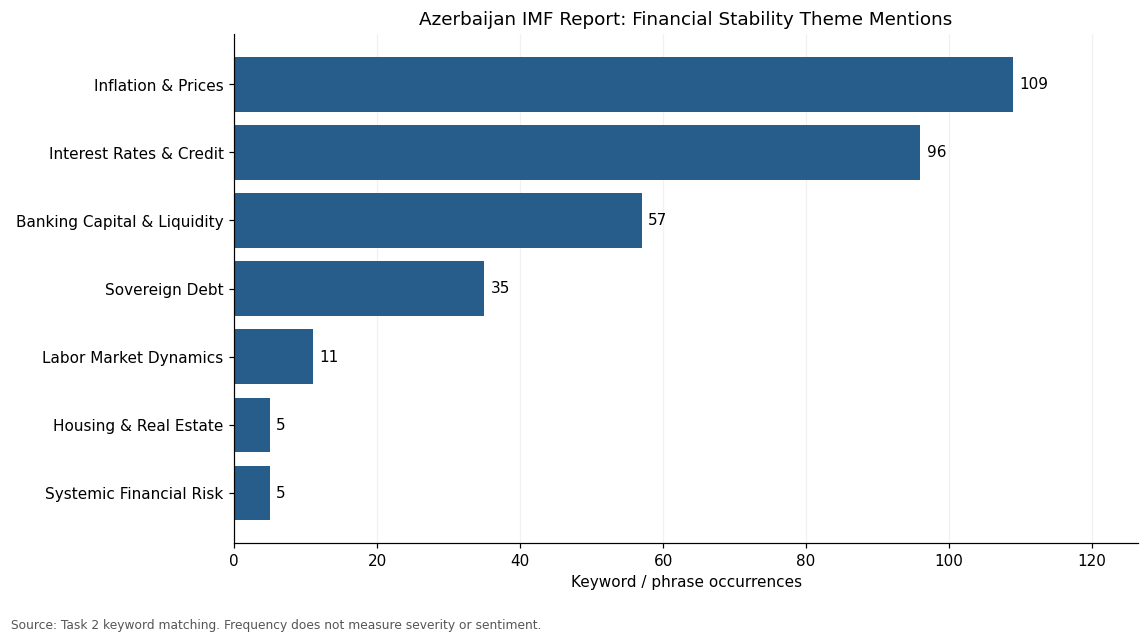

In [28]:
# Cell 5: Chart 1 — frequency of seven financial stability themes
t = themes.copy().sort_values('count', ascending=True)
t['count'] = pd.to_numeric(t['count'], errors='coerce').fillna(0)
fig,ax = plt.subplots(figsize=(10.5,5.8))
bars = ax.barh(t['theme'], t['count'], color='#275d8a')
ax.bar_label(bars, padding=4, fmt='%.0f')
ax.set(xlabel='Keyword / phrase occurrences', title='Azerbaijan IMF Report: Financial Stability Theme Mentions')
ax.set_xlim(0, max(t['count'])*1.16 if len(t) else 1)
ax.grid(axis='x',alpha=.17); ax.set_axisbelow(True)
fig.text(.01,.005,'Source: Task 2 keyword matching. Frequency does not measure severity or sentiment.',fontsize=8,color='#555555')
fig.tight_layout(rect=(0,.04,1,1)); fig.savefig(OUT/'01_theme_mentions.png', dpi=300,bbox_inches='tight'); plt.show()

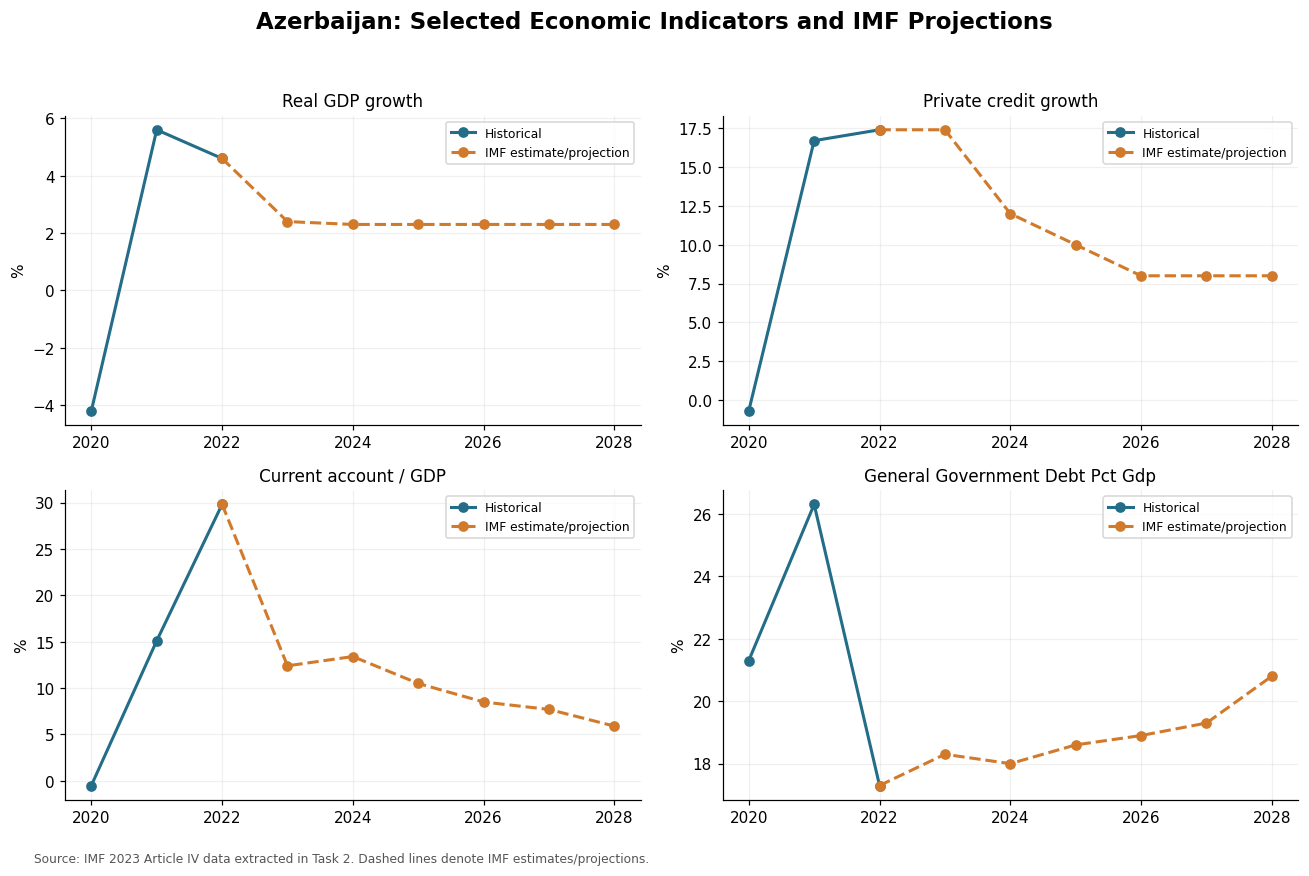

In [29]:
# Cell 6: Chart 2 — economic time-series with historical vs projected values
# Uses the original IMF values and their status labels; never invents missing years.
labels = {'real_gdp_growth_pct':'Real GDP growth','inflation_end_period_pct':'End-year inflation','inflation_average_pct':'Average inflation','public_debt_pct_gdp':'Public debt / GDP','private_credit_growth_pct':'Private credit growth','current_account_pct_gdp':'Current account / GDP'}
series = list(tidy['indicator'].dropna().unique())
priority = [k for k in labels if k in series]
selected = (priority + [k for k in series if k not in priority])[:4]
fig,axs = plt.subplots(2,2,figsize=(12,8),sharex=False)
for ax,k in zip(axs.flat,selected):
    d = tidy[tidy.indicator==k].sort_values('year')
    hist = d[d.status.astype(str).str.lower().eq('historical')]
    proj = d[~d.status.astype(str).str.lower().eq('historical')]
    if len(hist): ax.plot(hist.year.astype(int),hist.value_pct,marker='o',color='#236d89',lw=2,label='Historical')
    if len(proj):
        bridge = pd.concat([hist.tail(1),proj]).sort_values('year') if len(hist) else proj
        ax.plot(bridge.year.astype(int),bridge.value_pct,marker='o',linestyle='--',color='#d17a2c',lw=2,label='IMF estimate/projection')
    ax.set_title(labels.get(k,k.replace('_',' ').title()),fontsize=11)
    ax.set_ylabel('%' if 'pct' in k else 'Value'); ax.grid(alpha=.18); ax.xaxis.set_major_locator(MaxNLocator(integer=True,nbins=6))
    ax.legend(fontsize=8,loc='best')
for ax in list(axs.flat)[len(selected):]: ax.axis('off')
fig.suptitle('Azerbaijan: Selected Economic Indicators and IMF Projections',fontweight='bold',fontsize=15)
fig.text(.03,.012,'Source: IMF 2023 Article IV data extracted in Task 2. Dashed lines denote IMF estimates/projections.',fontsize=8,color='#555555')
fig.tight_layout(rect=(0,.035,1,.95));fig.savefig(OUT/'02_economic_trends.png',dpi=300,bbox_inches='tight');plt.show()

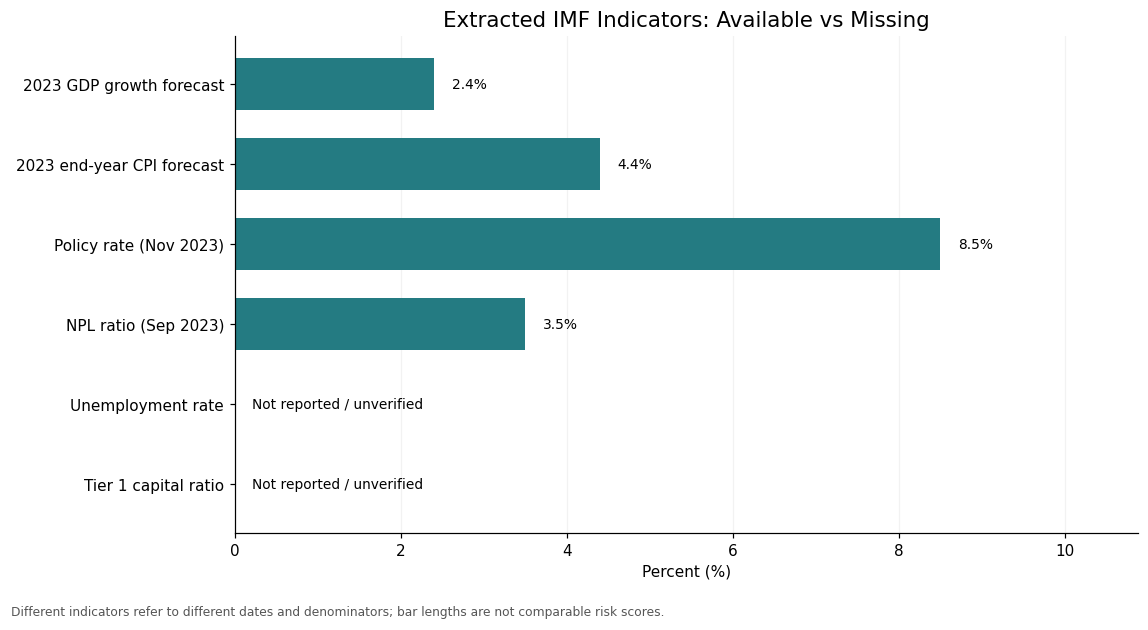

In [30]:
# Cell 7: Chart 3 — verified indicators, with missing values clearly marked
indicator_labels = {'gdp_growth_forecast_pct':'2023 GDP growth forecast','headline_inflation_rate_pct':'2023 end-year CPI forecast','central_bank_policy_rate_pct':'Policy rate (Nov 2023)','non_performing_loan_ratio':'NPL ratio (Sep 2023)','unemployment_rate_pct':'Unemployment rate','tier_1_capital_ratio':'Tier 1 capital ratio'}
rows = [(label,indicators.get(key)) for key,label in indicator_labels.items()]
vals = [float(v) if isinstance(v,(int,float)) and not isinstance(v,bool) and np.isfinite(v) else np.nan for _,v in rows]
fig,ax=plt.subplots(figsize=(10.5,5.7))
y=np.arange(len(rows)); bars=ax.barh(y,[v if np.isfinite(v) else 0 for v in vals],color=['#247b82' if np.isfinite(v) else '#c8c8c8' for v in vals],height=.65)
ax.set_yticks(y,[label for label,_ in rows]);ax.invert_yaxis()
maxv=max([v for v in vals if np.isfinite(v)] or [1]);ax.set_xlim(0,maxv*1.28)
for i,v in enumerate(vals): ax.text((v if np.isfinite(v) else 0)+maxv*.025,i,f'{v:g}%' if np.isfinite(v) else 'Not reported / unverified',va='center',fontsize=9)
ax.set_xlabel('Percent (%)');ax.set_title('Extracted IMF Indicators: Available vs Missing',fontsize=14)
ax.grid(axis='x',alpha=.16);ax.set_axisbelow(True)
fig.text(.01,.008,'Different indicators refer to different dates and denominators; bar lengths are not comparable risk scores.',fontsize=8,color='#555555')
fig.tight_layout(rect=(0,.04,1,1));fig.savefig(OUT/'03_core_indicators.png',dpi=300,bbox_inches='tight');plt.show()

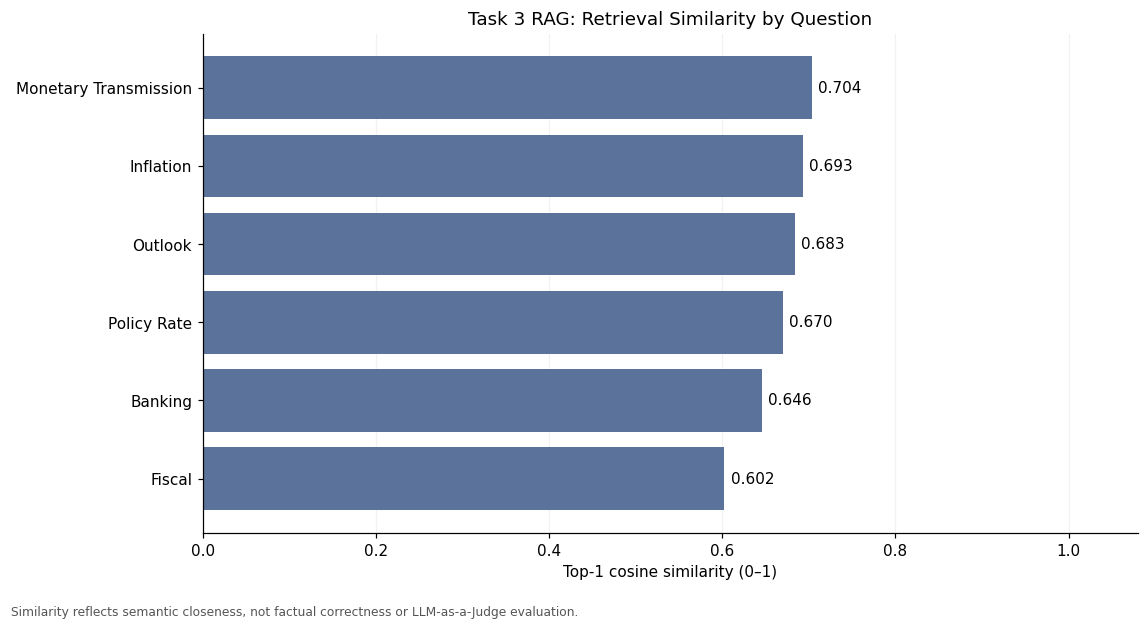

In [34]:
# Cell 8: Chart 4 — RAG retrieval diagnostics (not LLM judge scores)
fig,ax=plt.subplots(figsize=(10.5,5.7))
if rag is not None and {'query_id','top1_cosine'}.issubset(rag.columns):
    r=rag.copy();r['top1_cosine']=pd.to_numeric(r['top1_cosine'],errors='coerce');r=r.dropna(subset=['top1_cosine']).sort_values('top1_cosine')
    bars=ax.barh(r['query_id'].str.replace('_',' ',regex=False).str.title(),r['top1_cosine'],color='#5b729a')
    ax.bar_label(bars,padding=4,fmt='%.3f');ax.set_xlim(0,1.08);ax.set_xlabel('Top-1 cosine similarity (0–1)')
    ax.set_title('Task 3 RAG: Retrieval Similarity by Question')
    ax.grid(axis='x',alpha=.17);ax.set_axisbelow(True)
    note='Similarity reflects semantic closeness, not factual correctness or LLM-as-a-Judge evaluation.'
else:
    ax.text(.5,.5,'Task 3 RAG diagnostics were not supplied.\nUpload Task 3 ZIP to populate this chart.',ha='center',va='center',transform=ax.transAxes)
    ax.set_axis_off();note='No RAG diagnostic data supplied; no scores were fabricated.'
fig.text(.01,.008,note,fontsize=8,color='#555555')
fig.tight_layout(rect=(0,.04,1,1));fig.savefig(OUT/'04_rag_retrieval_diagnostics.png',dpi=300,bbox_inches='tight');plt.show()

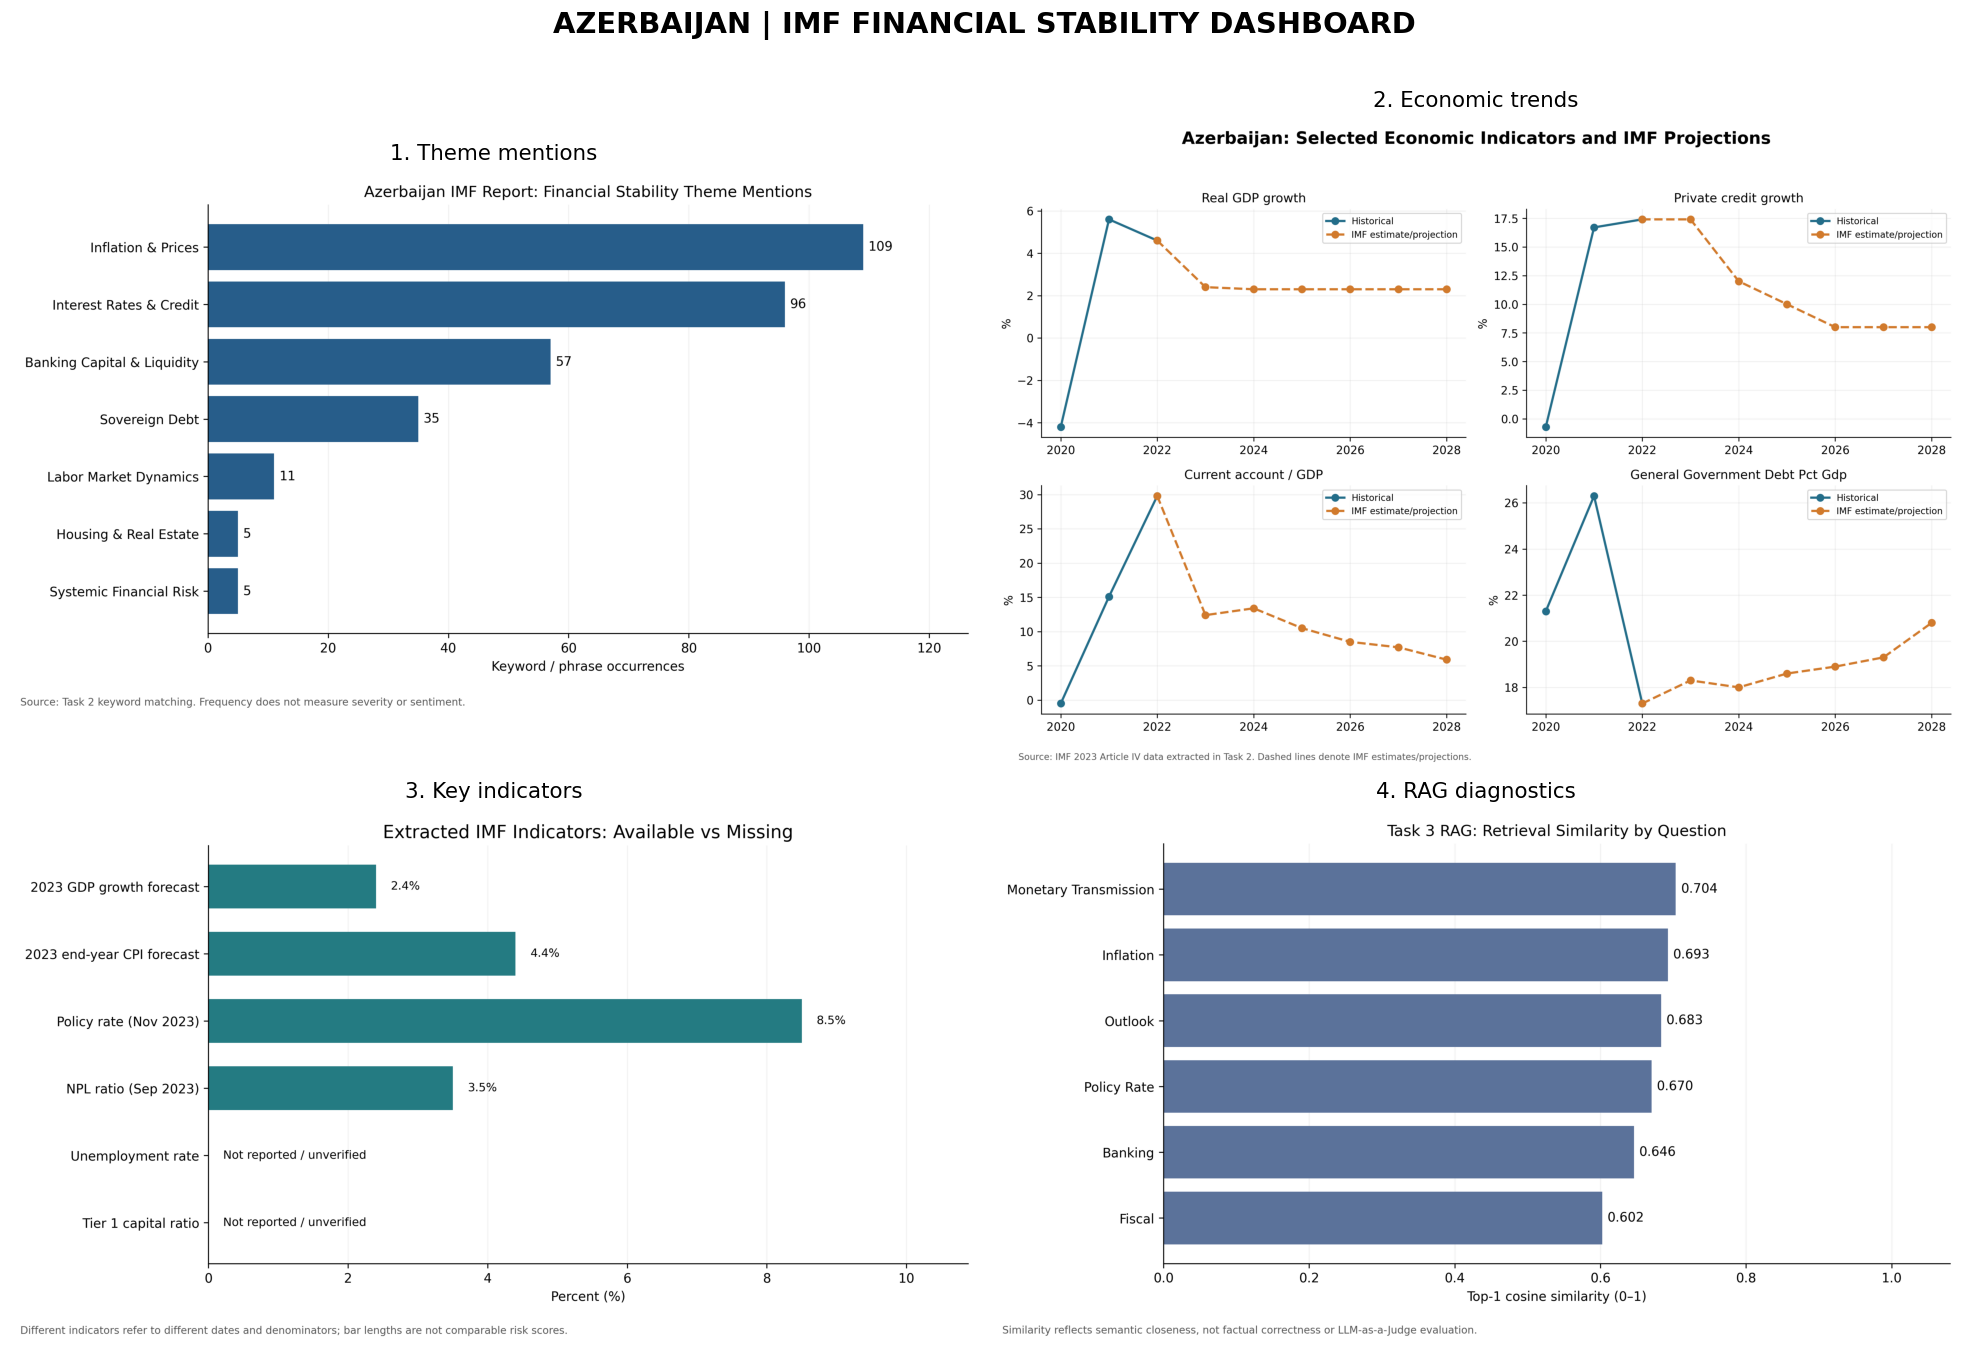

In [35]:
# Cell 9: create a single dashboard image from the four original PNGs
# This is an optional overview; the four individual 300-DPI charts remain the primary deliverables.
fig,axs=plt.subplots(2,2,figsize=(18,13))
for ax,(fname,title) in zip(axs.flat,[('01_theme_mentions.png','1. Theme mentions'),('02_economic_trends.png','2. Economic trends'),('03_core_indicators.png','3. Key indicators'),('04_rag_retrieval_diagnostics.png','4. RAG diagnostics')]):
    ax.imshow(plt.imread(OUT/fname));ax.axis('off');ax.set_title(title,fontsize=14,pad=12)
fig.suptitle('AZERBAIJAN | IMF FINANCIAL STABILITY DASHBOARD',fontsize=19,fontweight='bold',y=.99)
fig.tight_layout(rect=(0,0,1,.97));fig.savefig(OUT/'00_combined_dashboard.png',dpi=300,bbox_inches='tight');plt.show()

In [36]:
# Cell 10: write provenance, quality checks, and downloadable ZIP
quality = {
 'country':'Azerbaijan','task':'Task 4','chart_count':4,'chart_dpi':300,
 'task2_theme_count':int(len(themes)), 'task2_trend_records':int(len(tidy)),
 'missing_core_indicators':[k for k in indicator_labels if indicators.get(k) is None],
 'rag_questions':int(len(rag)) if rag is not None else 0,
 'uses_pd_melt':True,
 'llm_judge_scores_included':False,
 'cautions':['Theme counts are keyword matches, not risk severity.', 'RAG cosine similarity is not an LLM judge score.', 'IMF projections must not be presented as realised historical values.', 'Unavailable indicators remain missing.']
}
(OUT/'task4_quality_report.json').write_text(json.dumps(quality,indent=2),encoding='utf-8')
(OUT/'README.txt').write_text('Azerbaijan Task 4 — 300 DPI financial stability dashboard.\nCharts 01-04 are the four required distinct visualisations.\nChart 00 is a combined overview.\nTidy data produced via pandas pd.melt.\nNo fabricated missing indicators or LLM judge scores.\n',encoding='utf-8')
zip_name='Azerbaijan_Task4_Results.zip'
zip_out=OUT.parent/zip_name
with zipfile.ZipFile(zip_out,'w',zipfile.ZIP_DEFLATED) as z:
    for f in OUT.iterdir():
        if f.is_file():z.write(f,arcname=f.name)
print('Created:',zip_out,'Size (MB):',round(zip_out.stat().st_size/1e6,2))
print(json.dumps(quality,indent=2))
from google.colab import files
files.download(str(zip_out))

Created: /content/Azerbaijan_Task4_Results.zip Size (MB): 1.72
{
  "country": "Azerbaijan",
  "task": "Task 4",
  "chart_count": 4,
  "chart_dpi": 300,
  "task2_theme_count": 7,
  "task2_trend_records": 54,
  "missing_core_indicators": [
    "unemployment_rate_pct",
    "tier_1_capital_ratio"
  ],
  "rag_questions": 6,
  "uses_pd_melt": true,
  "llm_judge_scores_included": false,
  "cautions": [
    "Theme counts are keyword matches, not risk severity.",
    "RAG cosine similarity is not an LLM judge score.",
    "IMF projections must not be presented as realised historical values.",
    "Unavailable indicators remain missing."
  ]
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>